# Chapitre 5 - Exercices 5.11 à 5.15

Noyau de la matrice de pénalité, poids et ex-æquo, validation croisée par augmentation
de l'échantillon, contraintes des splines de plaque mince, propriétés des RKHS.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch05_splines import SmoothingSpline, loocv_score
set_style()

## Exercice 5.11 : Noyau de la matrice de pénalité

**Énoncé.** Montrer que, pour une spline de lissage, le noyau de la matrice de pénalité
$\mathbf K$ (forme de Reinsch $\mathbf S_\lambda = (\mathbf I + \lambda\mathbf K)^{-1}$)
est engendré par les fonctions linéaires en $X$.

**Rappels.** Avec $x_1 < \dots < x_N$ distincts ($N \ge 2$), $\mathbf N$ la matrice
(inversible) de la base naturelle aux $x_i$ et $\mathbf K = \mathbf N^{-T}\Omega_N\mathbf
N^{-1}$ (exercice 5.9). Pour $\mathbf f \in \mathbb R^N$, soit $\theta = \mathbf
N^{-1}\mathbf f$ et $\hat f = \sum_j\theta_jN_j$ la spline naturelle interpolant les
valeurs $\mathbf f$ aux $x_i$. Alors

$$
\mathbf f^T\mathbf K\mathbf f = \theta^T\Omega_N\theta = \int\hat f''(t)^2\,dt .
$$

**Solution.** $\mathbf K$ est symétrique semi-définie positive. Pour une telle matrice,
$\mathbf K\mathbf f = 0 \iff \mathbf f^T\mathbf K\mathbf f = 0$. En effet, en diagonalisant
$\mathbf K = \sum_kd_k\mathbf u_k\mathbf u_k^T$ ($d_k \ge 0$),
$\mathbf f^T\mathbf K\mathbf f = \sum_kd_k\langle\mathbf u_k, \mathbf f\rangle^2$ est nul
ssi $\langle\mathbf u_k, \mathbf f\rangle = 0$ pour tout $k$ tel que $d_k > 0$, ssi
$\mathbf K\mathbf f = \sum_kd_k\langle\mathbf u_k, \mathbf f\rangle\mathbf u_k = 0$.

Or $\int\hat f''^2 = 0 \iff \hat f'' \equiv 0$ (fonction continue, positive, d'intégrale
nulle) $\iff \hat f$ affine $\iff f_i = a + bx_i$ pour tout $i$ (si les $f_i$ sont alignés,
la droite est une spline naturelle qui les interpole, et c'est la seule par unicité).
Donc

$$
\ker\mathbf K = \{(a + bx_i)_{i=1..N} : a, b \in \mathbb R\} = \mathrm{Vect}(\mathbf 1, \mathbf x),
$$

de dimension 2. Conséquence : $\mathbf S_\lambda\mathbf f = \mathbf f$ pour $\mathbf f$
affine, quel que soit $\lambda$ (les deux valeurs propres $\rho_k = 1$ du cours 2).

**Vérification numérique** : on reconstitue $\mathbf K = (\mathbf S_\lambda^{-1} -
\mathbf I)/\lambda$ et l'on examine ses plus petites valeurs propres et les vecteurs propres
associés.

In [2]:
rng = np.random.RandomState(0)
n = 50
x = np.sort(rng.uniform(0, 1, n))
lam = 1e-3
S = SmoothingSpline(lam=lam).fit(x, np.zeros(n)).smoother_matrix()
K = (np.linalg.inv(S) - np.eye(n)) / lam
K = (K + K.T) / 2
d, U = np.linalg.eigh(K)
print("3 plus petites valeurs propres de K :", np.round(d[:3], 6) + 0.0)
P = np.column_stack([np.ones(n), x])
proj = P @ np.linalg.lstsq(P, U[:, :2], rcond=None)[0]
print("résidu de projection des 2 premiers vecteurs propres sur Vect(1, x) :", np.abs(proj - U[:, :2]).max())
v = 2 - 3 * x
print("||K v|| / (||K|| ||v||) pour v = 2 - 3x :", np.linalg.norm(K @ v) / (np.linalg.norm(K, 2) * np.linalg.norm(v)))

3 plus petites valeurs propres de K : [0.       0.       9.301486]
résidu de projection des 2 premiers vecteurs propres sur Vect(1, x) : 3.015522886951061e-09
||K v|| / (||K|| ||v||) pour v = 2 - 3x : 7.367887060510247e-15


> **À retenir.** $\mathbf f^T\mathbf K\mathbf f$ est la courbure de l'interpolant
> naturel ; elle s'annule exactement pour les vecteurs alignés : le noyau de $\mathbf K$
> est $\mathrm{Vect}(\mathbf 1, \mathbf x)$, et ces composantes ne sont jamais rétrécies.

## Exercice 5.12 : Poids et observations ex æquo

**Énoncé.** Caractériser la solution de (éq. (5.73))

$$
\min_f\ \sum_{i=1}^{N}w_i\{y_i - f(x_i)\}^2 + \lambda\int\{f''(t)\}^2dt,\qquad w_i \ge 0 .
$$

Caractériser ensuite la solution de (5.9) lorsque les $x_i$ présentent des ex æquo.

**Poids.** L'argument de l'exercice 5.7 s'applique tel quel : remplacer $f$ par la spline
naturelle $g$ interpolant les valeurs $f(x_i)$ ne change pas le premier terme (pondéré ou
non) et ne peut que diminuer la pénalité. La solution est donc une **spline cubique
naturelle à nœuds aux valeurs distinctes des $x_i$** (celles de poids nul peuvent être
omises). Dans la base naturelle, avec $\mathbf W = \mathrm{diag}(w_i)$ :

$$
(\mathbf y - \mathbf N\theta)^T\mathbf W(\mathbf y - \mathbf N\theta) + \lambda\theta^T\Omega_N\theta
\quad\Longrightarrow\quad
\hat\theta = (\mathbf N^T\mathbf W\mathbf N + \lambda\Omega_N)^{-1}\mathbf N^T\mathbf W\mathbf y,
$$

et $\hat{\mathbf f} = \mathbf S_{\lambda,w}\mathbf y$ avec
$\mathbf S_{\lambda,w} = \mathbf N(\mathbf N^T\mathbf W\mathbf N + \lambda\Omega_N)^{-1}
\mathbf N^T\mathbf W$ (non symétrique en général). Quand $\mathbf N$ est carrée inversible
et $\mathbf W$ inversible : $\mathbf S_{\lambda,w} = (\mathbf I + \lambda\mathbf W^{-1}\mathbf K)^{-1}$.
C'est ce lisseur pondéré qui intervient dans la régression logistique non paramétrique
(éq. (5.33)-(5.34)).

**Ex æquo.** Supposons que les $x_i$ prennent $n < N$ valeurs distinctes $u_1, \dots,
u_n$, la valeur $u_j$ étant prise $n_j$ fois, avec moyenne des réponses
$\bar y_j = \frac1{n_j}\sum_{i : x_i = u_j}y_i$. Pour tout $f$, en développant
$y_i - f(u_j) = (y_i - \bar y_j) + (\bar y_j - f(u_j))$ et en remarquant que
$\sum_{i : x_i = u_j}(y_i - \bar y_j) = 0$ (le double produit disparaît) :

$$
\sum_{i=1}^{N}\{y_i - f(x_i)\}^2 = \sum_{j=1}^{n}n_j\{\bar y_j - f(u_j)\}^2
  + \underbrace{\sum_{j}\sum_{i : x_i = u_j}(y_i - \bar y_j)^2}_{\text{indépendant de } f}.
$$

Le problème (5.9) avec ex æquo équivaut donc à une **spline de lissage pondérée** sur les
$n$ points $(u_j, \bar y_j)$ avec poids $w_j = n_j$ : spline naturelle à $n$ nœuds, de
matrice de lissage $n \times n$.

**Vérification** sur les données *bone* (filles), qui comportent de nombreux ex æquo.

In [3]:
bone = datasets.load_bone()
fem = bone[bone["gender"] == "female"]
xa, ya = fem["age"].to_numpy(), fem["spnbmd"].to_numpy()
agr = fem.groupby("age")["spnbmd"].agg(["mean", "size"]).reset_index()
print("N = %d observations, n = %d âges distincts" % (len(xa), len(agr)))
lam = 1.0
s_full = SmoothingSpline(lam=lam).fit(xa, ya)
s_agr = SmoothingSpline(lam=lam).fit(agr["age"].to_numpy(), agr["mean"].to_numpy(),
                                     w=agr["size"].to_numpy(float))
grille = np.linspace(xa.min(), xa.max(), 300)
print("écart max entre les deux ajustements :", np.abs(s_full.predict(grille) - s_agr.predict(grille)).max())
print("ddl : %.4f (données complètes) vs %.4f (moyennes pondérées)" % (s_full.df_, s_agr.df_))

N = 259 observations, n = 168 âges distincts
écart max entre les deux ajustements : 3.427952366408249e-13
ddl : 12.1463 (données complètes) vs 12.1463 (moyennes pondérées)


**Effet des poids.** Donnons un poids 20 fois plus fort aux observations d'âge supérieur à
20 ans : la courbe s'en rapproche (comportement d'un ajustement pondéré).

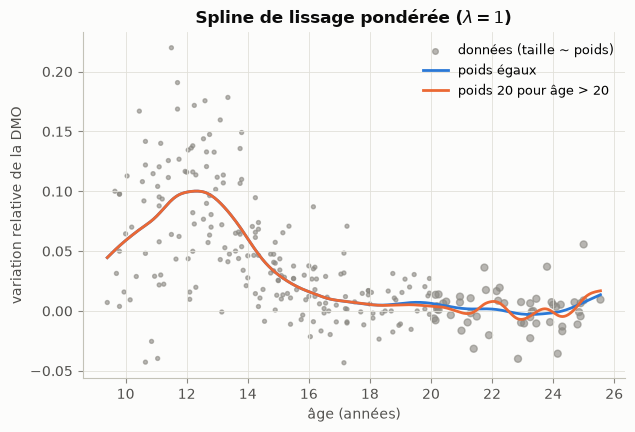

In [4]:
w = np.where(xa > 20, 20.0, 1.0)
s_w = SmoothingSpline(lam=lam).fit(xa, ya, w=w)
plt.figure(figsize=(7, 4.5))
plt.scatter(xa, ya, s=np.where(xa > 20, 25, 8), color=GRAY, alpha=0.6, label="données (taille ~ poids)")
plt.plot(grille, s_full.predict(grille), color=BLUE, label="poids égaux")
plt.plot(grille, s_w.predict(grille), color=ORANGE, label="poids 20 pour âge > 20")
plt.xlabel("âge (années)")
plt.ylabel("variation relative de la DMO")
plt.title("Spline de lissage pondérée ($\\lambda = 1$)")
plt.legend()
plt.show()

> **À retenir.** Avec des poids, la solution reste une spline naturelle à nœuds aux $x_i$
> distincts, obtenue par ridge généralisée pondérée. Des ex æquo se traitent en remplaçant
> chaque groupe par sa moyenne, pondérée par l'effectif.

## Exercice 5.13 : Augmenter l'échantillon par un point ajusté ; formule de la CV

**Énoncé.** On a ajusté une spline de lissage $\hat f_\lambda$ à $N$ couples $(x_i, y_i)$.
On ajoute le couple $(x_0, \hat f_\lambda(x_0))$ et l'on réajuste (même $\lambda$).
Décrire le résultat, et en déduire la formule (5.26)-(5.27) de la validation croisée
« leave-one-out ».

**Le résultat ne change pas.** Notons $R_N(f) = \sum_{i=1}^{N}(y_i - f(x_i))^2 +
\lambda\int f''^2$ et $R_{N+1}(f) = R_N(f) + (\hat f_\lambda(x_0) - f(x_0))^2$ le critère
augmenté. Pour toute $f$ :

$$
R_{N+1}(f) \;\ge\; R_N(f) \;\ge\; R_N(\hat f_\lambda) \;=\; R_{N+1}(\hat f_\lambda),
$$

(le terme ajouté est $\ge 0$ ; $\hat f_\lambda$ minimise $R_N$ ; le terme ajouté est nul
en $\hat f_\lambda$). Donc $\hat f_\lambda$ minimise aussi $R_{N+1}$, et par unicité du
minimiseur, le réajustement redonne **exactement** $\hat f_\lambda$.

**Formule de la CV.** Soit $\hat f^{(-i)}$ la spline ajustée sans l'observation $i$.
D'après ce qui précède, ajouter le point $(x_i, \hat f^{(-i)}(x_i))$ à l'échantillon privé
de $i$ redonne $\hat f^{(-i)}$. Mais cet échantillon augmenté est l'échantillon complet où
$y_i$ est remplacé par $y_i^* = \hat f^{(-i)}(x_i)$ : mêmes $x$, même $\lambda$, donc même
matrice de lissage $\mathbf S_\lambda$. En notant $\mathbf y^*$ ce vecteur :

$$
\hat f^{(-i)}(x_i) = \sum_{j \ne i}S_{ij}y_j + S_{ii}\hat f^{(-i)}(x_i),\qquad
\hat f_\lambda(x_i) = \sum_{j \ne i}S_{ij}y_j + S_{ii}y_i .
$$

En soustrayant : $\hat f^{(-i)}(x_i) - \hat f_\lambda(x_i) = S_{ii}(\hat f^{(-i)}(x_i) -
y_i)$. Posons $r_i = y_i - \hat f^{(-i)}(x_i)$ ; alors
$y_i - \hat f_\lambda(x_i) = r_i + (\hat f^{(-i)}(x_i) - \hat f_\lambda(x_i)) = r_i -
S_{ii}r_i$, d'où

$$
y_i - \hat f^{(-i)}(x_i) = \frac{y_i - \hat f_\lambda(x_i)}{1 - S_{ii}},\qquad
\mathrm{CV}(\hat f_\lambda) = \frac1N\sum_{i=1}^{N}\left(\frac{y_i - \hat
f_\lambda(x_i)}{1 - S_\lambda(i,i)}\right)^2 .
$$

**Vérifications numériques.** D'abord l'invariance par ajout d'un point ajusté, puis la
formule des résidus « leave-one-out », observation par observation.

In [5]:
rng = np.random.RandomState(3)
n = 60
x = np.sort(rng.uniform(0, 1, n))
fsim = lambda t: np.sin(12 * (t + 0.2)) / (t + 0.2)
y = fsim(x) + rng.randn(n)
lam = 1e-5
s = SmoothingSpline(lam=lam).fit(x, y)
x0 = 0.4321
s_aug = SmoothingSpline(lam=lam).fit(np.r_[x, x0], np.r_[y, s.predict(np.array([x0]))])
g = np.linspace(0, 1, 500)
print("écart max entre ajustement initial et augmenté :", np.abs(s.predict(g) - s_aug.predict(g)).max())

écart max entre ajustement initial et augmenté : 4.1966430330830917e-13


In [6]:
Sm = s.smoother_matrix()
r_formule = (y - Sm @ y) / (1 - np.diag(Sm))
r_direct = np.array([y[i] - SmoothingSpline(lam=lam).fit(np.delete(x, i), np.delete(y, i))
                     .predict(x[i:i + 1])[0] for i in range(n)])
print("écart max entre résidus LOO directs et formule :", np.abs(r_formule - r_direct).max())
print("CV = %.5f (formule) = %.5f (direct)" % (np.mean(r_formule ** 2), np.mean(r_direct ** 2)))

écart max entre résidus LOO directs et formule : 4.425348976155874e-13
CV = 1.30197 (formule) = 1.30197 (direct)


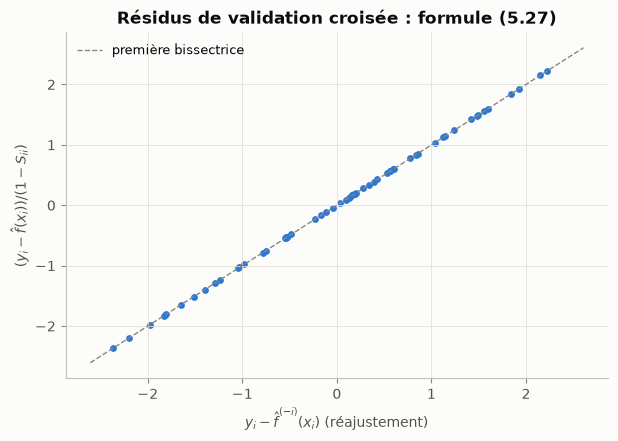

In [7]:
plt.figure(figsize=(7, 4.5))
plt.scatter(r_direct, r_formule, s=15, color=BLUE)
lim = np.abs(r_direct).max() * 1.1
plt.plot([-lim, lim], [-lim, lim], color=GRAY, lw=1, ls="--", label="première bissectrice")
plt.xlabel(r"$y_i - \hat f^{(-i)}(x_i)$ (réajustement)")
plt.ylabel(r"$(y_i - \hat f(x_i))/(1 - S_{ii})$")
plt.title("Résidus de validation croisée : formule (5.27)")
plt.legend()
plt.show()

> **À retenir.** Ajouter un point situé sur la courbe ajustée ne change rien. Cette
> remarque, combinée à la linéarité du lisseur, donne les résidus « leave-one-out » sans
> aucun réajustement : $r_i = (y_i - \hat f_i)/(1 - S_{ii})$. La même formule vaut pour
> tout lisseur linéaire ayant cette propriété (moindres carrés, ridge, ridge à noyau…).

## Exercice 5.14 : Splines de plaque mince : finitude de la pénalité

**Énoncé.** Pour le développement (5.39)
$f(x) = \beta_0 + \beta^Tx + \sum_{j=1}^{N}\alpha_jh_j(x)$, avec
$h_j(x) = \eta(\|x - x_j\|)$, $\eta(r) = r^2\log r$, $x \in \mathbb R^2$, établir les
contraintes sur les $\alpha_j$ garantissant que la pénalité $J(f)$ (5.38) est finie.
Comment assurer autrement la finitude de la pénalité ?

**Rappels.** $J(f) = \iint_{\mathbb R^2}\|\nabla^2 f(x)\|_F^2\,dx$, où $\nabla^2f$ est la
matrice hessienne et $\|\mathbf A\|_F^2 = \sum_{k,l}A_{kl}^2 = f_{11}^2 + 2f_{12}^2 +
f_{22}^2$. La partie affine $\beta_0 + \beta^Tx$ a une hessienne nulle.

**Hessienne de $g(x) = \|x\|^2\log\|x\|$.** Avec $r = \|x\|$ : $\nabla g = x\,(2\log r +
1)$ (car $\nabla r = x/r$), puis

$$
\nabla^2g(x) = (2\log r + 1)\,\mathbf I + 2\,\frac{xx^T}{r^2} =: \mathbf M(x).
$$

Ses coefficients croissent comme $\log r$ : $\iint\|\mathbf M\|_F^2$ diverge (comme
$\int^{\infty}(\log r)^2\,r\,dr$). Près de $x = 0$, la singularité en $\log r$ est de carré
intégrable : seul le comportement à l'infini pose problème.

**Développement à l'infini.** La hessienne de $f$ est $\sum_j\alpha_j\mathbf M(x - x_j)$.
Pour $\|x\| \to \infty$ et $x_j$ fixé, par un développement de Taylor à l'ordre 1 en
$x_j$ (les dérivées de $\mathbf M$ sont en $O(1/r)$, les dérivées secondes en $O(1/r^2)$) :

$$
\mathbf M(x - x_j) = \mathbf M(x) - D\mathbf M(x)[x_j] + O(r^{-2}).
$$

En sommant :

$$
\nabla^2f(x) = \Big(\sum_j\alpha_j\Big)\mathbf M(x) - D\mathbf M(x)\Big[\sum_j\alpha_jx_j\Big] + O(r^{-2}).
$$

- Si $\sum_j\alpha_j \ne 0$ : terme en $\log r$, $J = \infty$.
- Si $\sum_j\alpha_j = 0$ mais $\sum_j\alpha_jx_j \ne 0$ : terme en $1/r$, et
  $\int^{\infty}r^{-2}\,r\,dr = \int^\infty dr/r = \infty$ (divergence logarithmique).
- Si les deux sont nuls : $\nabla^2f = O(r^{-2})$ et $\int^{\infty}r^{-4}\,r\,dr < \infty$.

Les contraintes sont donc

$$
\sum_{j=1}^{N}\alpha_j = 0,\qquad \sum_{j=1}^{N}\alpha_jx_{j1} = 0,\qquad \sum_{j=1}^{N}\alpha_jx_{j2} = 0,
$$

soit $\mathbf T^T\alpha = 0$ avec $\mathbf T = [\mathbf 1, \mathbf X]$ ($N \times 3$) :
$\alpha$ est orthogonal aux polynômes de degré 1 (le noyau de la pénalité).

**Autres façons d'assurer la finitude.** On peut (i) n'intégrer la pénalité que sur un
**domaine borné** $\mathcal D$ contenant les données (par ex. un rectangle) - alors tout
$\alpha$ convient ; (ii) utiliser des fonctions de base à **support compact** (produits
tensoriels de B-splines, §5.7) avec une pénalité sur un domaine borné ; (iii) tronquer ou
modifier les fonctions radiales loin des données.

**Vérification numérique** : on calcule $\iint_{2 \le \|x\| \le R}\|\nabla^2f\|_F^2$ pour
des $\alpha$ quelconques, puis vérifiant seulement $\sum\alpha_j = 0$, puis vérifiant les
trois contraintes, quand $R$ grandit.

In [8]:
rng = np.random.RandomState(0)
Nc = 8
Xc = rng.uniform(-0.5, 0.5, (Nc, 2))
T = np.column_stack([np.ones(Nc), Xc])
a_libre = rng.randn(Nc)
a_somme = a_libre - a_libre.mean()
a_tps = a_libre - T @ np.linalg.lstsq(T, a_libre, rcond=None)[0]   # projection sur T^perp
print("T^T alpha (3 contraintes) :", np.round(T.T @ a_tps, 12) + 0.0)

def hess_norm2(pts, alpha):
    """||Hessienne||_F^2 de sum_j alpha_j eta(||x - x_j||) aux points pts (m x 2)."""
    H = np.zeros((len(pts), 2, 2))
    for a, xj in zip(alpha, Xc):
        u = pts - xj
        r2 = (u ** 2).sum(1)
        H += a * ((np.log(r2) + 1)[:, None, None] * np.eye(2)
                  + 2 * u[:, :, None] * u[:, None, :] / r2[:, None, None])
    return (H ** 2).sum((1, 2))

def integrale_couronne(alpha, R, nr=400, nth=128):
    """Intégrale sur 2 <= r <= R en coordonnées polaires (r = e^s, dr = r ds)."""
    s_ = np.linspace(np.log(2), np.log(R), nr)
    th = np.linspace(0, 2 * np.pi, nth, endpoint=False)
    S_, TH = np.meshgrid(s_, th, indexing="ij")
    r = np.exp(S_)
    pts = np.column_stack([(r * np.cos(TH)).ravel(), (r * np.sin(TH)).ravel()])
    vals = hess_norm2(pts, alpha).reshape(r.shape) * r ** 2     # jacobien r dr dtheta = r^2 ds dtheta
    return np.trapezoid(vals.mean(1) * 2 * np.pi, s_)

Rs = np.logspace(1, 5, 9)
res = {nom: [integrale_couronne(a, R) for R in Rs]
       for nom, a in [("alpha quelconque", a_libre), ("somme nulle seulement", a_somme),
                      ("3 contraintes", a_tps)]}

T^T alpha (3 contraintes) : [0. 0. 0.]


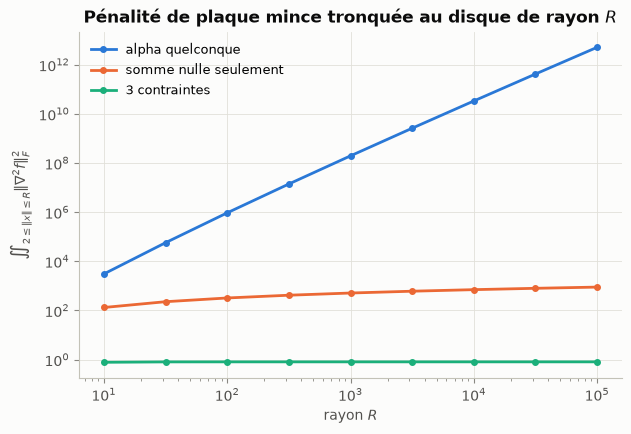

In [9]:
plt.figure(figsize=(7, 4.5))
for c, (nom, v) in zip(COLORS, res.items()):
    plt.loglog(Rs, v, "o-", color=c, ms=4, label=nom)
plt.xlabel("rayon $R$")
plt.ylabel(r"$\iint_{2 \leq \|x\| \leq R} \|\nabla^2 f\|_F^2$")
plt.title("Pénalité de plaque mince tronquée au disque de rayon $R$")
plt.legend()
plt.show()

Sans contrainte, l'intégrale croît comme $R^2(\log R)^2$ ; avec $\sum\alpha_j = 0$
seulement, elle croît comme $\log R$ (lentement, mais sans borne) ; avec les trois
contraintes, elle converge.

**Ajustement d'une spline de plaque mince.** On minimise $\|\mathbf y - \mathbf E\alpha -
\mathbf T\beta\|^2 + \lambda\alpha^T\mathbf E\alpha$ sous $\mathbf T^T\alpha = 0$, avec
$E_{ij} = \eta(\|x_i - x_j\|)$. Les conditions d'optimalité donnent le système linéaire
classique

$$
\begin{pmatrix}\mathbf E + \lambda\mathbf I & \mathbf T\\ \mathbf T^T & 0\end{pmatrix}
\begin{pmatrix}\alpha\\ \beta\end{pmatrix} = \begin{pmatrix}\mathbf y\\ 0\end{pmatrix}.
$$

In [10]:
rng = np.random.RandomState(1)
Np = 150
Xp = rng.uniform(0, 1, (Np, 2))
f2d = lambda Z: np.sin(3 * Z[:, 0]) * np.cos(4 * Z[:, 1])
yp = f2d(Xp) + 0.2 * rng.randn(Np)

def eta_mat(A, B):
    r = np.sqrt(((A[:, None, :] - B[None, :, :]) ** 2).sum(-1))
    return np.where(r > 0, r ** 2 * np.log(np.where(r > 0, r, 1.0)), 0.0)

E = eta_mat(Xp, Xp)
Tp = np.column_stack([np.ones(Np), Xp])
def plaque_mince(lam):
    """Inverse du système de plaque mince et matrice de lissage S (y -> valeurs ajustées)."""
    A = np.block([[E + lam * np.eye(Np), Tp], [Tp.T, np.zeros((3, 3))]])
    Ainv = np.linalg.inv(A)
    return Ainv, np.hstack([E, Tp]) @ Ainv[:, :Np]

# choix de lambda par validation croisée « leave-one-out » (lisseur linéaire, formule (5.27))
lams = np.logspace(-3, 0, 13)
cv = []
for l in lams:
    S_tp = plaque_mince(l)[1]
    cv.append(np.mean(((yp - S_tp @ yp) / (1 - np.diag(S_tp))) ** 2))
lam = lams[np.argmin(cv)]
Ainv, S_tp = plaque_mince(lam)
sol = Ainv[:, :Np] @ yp
alpha, beta = sol[:Np], sol[Np:]
print("lambda choisi par CV : %.3g ; ddl effectifs tr(S) = %.1f" % (lam, np.trace(S_tp)))
print("contraintes T^T alpha :", np.round(Tp.T @ alpha, 10) + 0.0)

lambda choisi par CV : 0.1 ; ddl effectifs tr(S) = 26.6
contraintes T^T alpha : [0. 0. 0.]


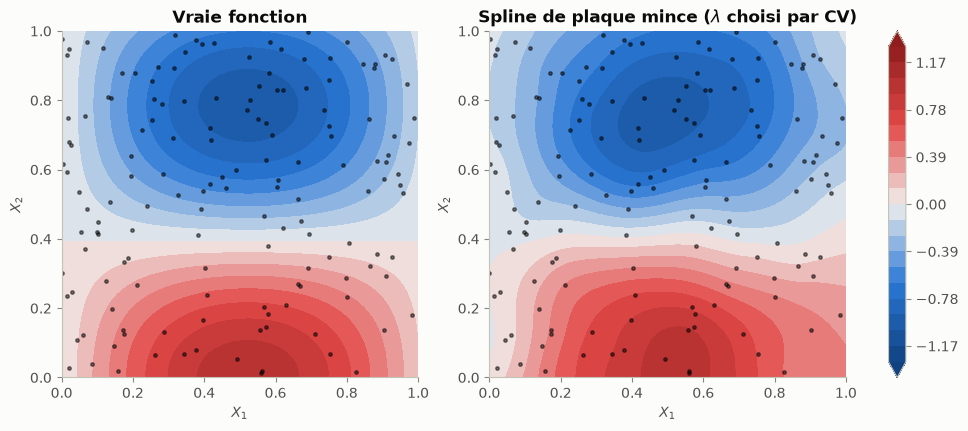

In [11]:
u = np.linspace(0, 1, 80)
G1, G2 = np.meshgrid(u, u)
Z = np.column_stack([G1.ravel(), G2.ravel()])
fit = (eta_mat(Z, Xp) @ alpha + np.column_stack([np.ones(len(Z)), Z]) @ beta).reshape(G1.shape)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, val, titre in [(axes[0], f2d(Z).reshape(G1.shape), "Vraie fonction"),
                       (axes[1], fit, "Spline de plaque mince ($\\lambda$ choisi par CV)")]:
    im = ax.contourf(G1, G2, val, levels=np.linspace(-1.3, 1.3, 21), cmap=DIV, extend="both")
    ax.grid(False)
    ax.scatter(Xp[:, 0], Xp[:, 1], s=6, color="k", alpha=0.5)
    ax.set_title(titre)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
fig.colorbar(im, ax=axes, fraction=0.03)
plt.show()

> **À retenir.** La pénalité de plaque mince n'est finie que si les coefficients des
> fonctions radiales sont orthogonaux aux polynômes de degré 1 :
> $\sum_j\alpha_j = 0$ et $\sum_j\alpha_jx_j = 0$.

## Exercice 5.15 : Propriétés d'un RKHS

**Énoncé.** Soit $K(x, y) = \sum_i\gamma_i\phi_i(x)\phi_i(y)$ vérifiant (5.45), et
$f \in \mathcal H_K$. Montrer :

(a) $\langle K(\cdot, x_i), f\rangle_{\mathcal H_K} = f(x_i)$ ;
(b) $\langle K(\cdot, x_i), K(\cdot, x_j)\rangle_{\mathcal H_K} = K(x_i, x_j)$ ;
(c) si $g(x) = \sum_{i=1}^{N}\alpha_iK(x, x_i)$, alors $J(g) = \sum_{i,j}K(x_i, x_j)\alpha_i\alpha_j$ ;
(d) si $\tilde g = g + \rho$ avec $\rho \in \mathcal H_K$ orthogonale dans $\mathcal H_K$ à
    chaque $K(\cdot, x_i)$, alors (éq. (5.74))
    $\sum_iL(y_i, \tilde g(x_i)) + \lambda J(\tilde g) \ge \sum_iL(y_i, g(x_i)) + \lambda J(g)$,
    avec égalité ssi $\rho = 0$.

**Rappels.** $\mathcal H_K = \{f = \sum_ic_i\phi_i : \sum_ic_i^2/\gamma_i < \infty\}$,
$\langle f, g\rangle_{\mathcal H_K} = \sum_ic_id_i/\gamma_i$ pour $f = \sum c_i\phi_i$,
$g = \sum d_i\phi_i$, et $J(f) = \|f\|^2_{\mathcal H_K}$. Les $\phi_i$ sont libres, donc
les coefficients d'une fonction sont uniques.

**(a)** À $x_i$ fixé, $K(\cdot, x_i) = \sum_k\gamma_k\phi_k(x_i)\,\phi_k(\cdot)$ a pour
coefficients $\gamma_k\phi_k(x_i)$. Elle est dans $\mathcal H_K$ car
$\sum_k(\gamma_k\phi_k(x_i))^2/\gamma_k = \sum_k\gamma_k\phi_k(x_i)^2 = K(x_i, x_i) < \infty$.
Pour $f = \sum_kc_k\phi_k$ :

$$
\langle K(\cdot, x_i), f\rangle_{\mathcal H_K} = \sum_k\frac{\gamma_k\phi_k(x_i)\,c_k}{\gamma_k}
  = \sum_kc_k\phi_k(x_i) = f(x_i).
$$

**(b)** On applique (a) à $f = K(\cdot, x_j) \in \mathcal H_K$ :
$\langle K(\cdot, x_i), K(\cdot, x_j)\rangle = K(x_i, x_j)$ (évaluation de
$K(\cdot, x_j)$ en $x_i$).

**(c)** Par bilinéarité du produit scalaire puis (b) :
$J(g) = \langle\sum_i\alpha_iK(\cdot, x_i), \sum_j\alpha_jK(\cdot, x_j)\rangle =
\sum_{i,j}\alpha_i\alpha_j\langle K(\cdot, x_i), K(\cdot, x_j)\rangle =
\sum_{i,j}K(x_i, x_j)\alpha_i\alpha_j = \alpha^T\mathbf K\alpha$.

**(d)** Par (a), $\rho(x_i) = \langle K(\cdot, x_i), \rho\rangle = 0$ pour tout $i$, donc
$\tilde g(x_i) = g(x_i)$ : les termes de perte sont **identiques**. Ensuite,
$\langle g, \rho\rangle = \sum_i\alpha_i\langle K(\cdot, x_i), \rho\rangle = 0$, donc
(Pythagore)

$$
J(\tilde g) = \|g + \rho\|^2 = \|g\|^2 + 2\langle g, \rho\rangle + \|\rho\|^2 = J(g) + \|\rho\|^2_{\mathcal H_K}.
$$

D'où (5.74) avec une différence égale à $\lambda\|\rho\|^2 \ge 0$, nulle ssi $\rho = 0$
(pour $\lambda > 0$). C'est le **théorème du représentant** : le minimiseur de (5.48)
appartient à $\mathrm{Vect}\{K(\cdot, x_1), \dots, K(\cdot, x_N)\}$.

**Vérification numérique** avec un noyau à développement explicite (tronqué à 40 termes)
sur $[0, 1]$ : $\phi_0 = 1$, $\phi_k(x) = \sqrt2\cos(k\pi x)$, $\gamma_0 = 1$,
$\gamma_k = (k\pi)^{-4}$ (les cosinus rapides, « rugueux », ont de petits $\gamma_k$). Une
fonction de $\mathcal H_K$ est représentée par son vecteur de coefficients $c$.

In [12]:
M = 40
kk = np.arange(M)
gam = np.where(kk == 0, 1.0, (np.maximum(kk, 1) * np.pi) ** -4.0)
phi = lambda x: np.where(kk == 0, 1.0, np.sqrt(2) * np.cos(np.outer(np.atleast_1d(x), kk) * np.pi))
Kfun = lambda x, y: (phi(x) * gam) @ phi(y).T
ps = lambda c, d: np.sum(c * d / gam)           # produit scalaire de H_K
coef_K = lambda xi: gam * phi(xi)[0]             # coefficients de K(., xi)

rng = np.random.RandomState(0)
xs = rng.uniform(0, 1, 6)
c_f = rng.randn(M) * np.sqrt(gam)                # une fonction f de H_K
print("(a) <K(.,x1), f> = %.6f ; f(x1) = %.6f" % (ps(coef_K(xs[0]), c_f), (phi(xs[0]) @ c_f)[0]))
print("(b) <K(.,x1), K(.,x2)> = %.6f ; K(x1, x2) = %.6f"
      % (ps(coef_K(xs[0]), coef_K(xs[1])), Kfun(xs[0], xs[1])[0, 0]))
al = rng.randn(6)
c_g = sum(a * coef_K(x) for a, x in zip(al, xs))
print("(c) J(g) = %.6f ; alpha^T K alpha = %.6f" % (ps(c_g, c_g), al @ Kfun(xs, xs) @ al))

(a) <K(.,x1), f> = 0.954073 ; f(x1) = 0.954073
(b) <K(.,x1), K(.,x2)> = 1.002253 ; K(x1, x2) = 1.002253
(c) J(g) = 7.912436 ; alpha^T K alpha = 7.912436


Pour (d), on construit $\rho$ orthogonale (dans $\mathcal H_K$) aux $K(\cdot, x_i)$ en
projetant un vecteur aléatoire, et l'on compare le critère pénalisé (perte quadratique)
de $g$ et de $g + \rho$.

In [13]:
Ck = np.array([coef_K(x) for x in xs])           # 6 x M
Gram = Ck @ np.diag(1 / gam) @ Ck.T              # = K(x_i, x_j)
c_r = rng.randn(M) * np.sqrt(gam)
c_r = c_r - Ck.T @ np.linalg.solve(Gram, Ck @ (c_r / gam))   # projection orthogonale dans H_K
y_obs = rng.randn(6)
crit = lambda c, lam=0.1: np.sum((y_obs - phi(xs) @ c) ** 2) + lam * ps(c, c)
print("max |rho(x_i)| =", np.abs(phi(xs) @ c_r).max())
print("critère(g) = %.6f ; critère(g + rho) = %.6f ; lambda ||rho||^2 = %.6f"
      % (crit(c_g), crit(c_g + c_r), 0.1 * ps(c_r, c_r)))

max |rho(x_i)| = 9.928444785062274e-13
critère(g) = 75.820422 ; critère(g + rho) = 78.647093 ; lambda ||rho||^2 = 2.826671


> **À retenir.** Les propriétés reproduisantes (a)-(b) font de $K(\cdot, x_i)$ le
> « représentant » de l'évaluation en $x_i$. Toute composante orthogonale aux
> $K(\cdot, x_i)$ est invisible aux données mais augmente la pénalité : la solution
> s'écrit $\sum_i\alpha_iK(\cdot, x_i)$ et $J = \alpha^T\mathbf K\alpha$.